# Hierarchical Priors: A Worked Example

## Introduction to Hierarchical Modeling

**Hierarchical modeling** is a Bayesian technique for analyzing data with natural multi-level structure.

### The Key Insight

Hierarchical priors enable learning at multiple scales simultaneously:
- Learn about individual groups (school-specific effects)
- Learn about population structure (overall variation)
- Automatically share information across groups (shrinkage)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print('Libraries imported. Ready!')

Libraries imported. Ready!


## Generate Data: Test Scores Across 15 Schools

We simulate test scores with:
- Different true means for each school
- Unequal sample sizes (10 to 100 students per school)
- Realistic measurement noise

In [3]:
n_schools = 15
true_mu_0 = 75.0        # Population mean
true_tau = 8.0          # Population std dev
true_sigma = 5.0        # Observation noise

true_school_means = np.random.normal(true_mu_0, true_tau, n_schools)
sample_sizes = np.array([10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 70, 80, 90, 100])

observed_data = []
for j in range(n_schools):
    scores = np.random.normal(true_school_means[j], true_sigma, sample_sizes[j])
    observed_data.append(scores)

sample_means = np.array([d.mean() for d in observed_data])

print('Data Summary')
print('=' * 70)
print(f'Population mean (μ₀): {true_mu_0:.2f}')
print(f'Population std (τ): {true_tau:.2f}')
print(f'Observation noise (σ): {true_sigma:.2f}')
print(f'\nTrue school means: {np.round(true_school_means, 1)}')
print('=' * 70)

Data Summary
Population mean (μ₀): 75.00
Population std (τ): 8.00
Observation noise (σ): 5.00

True school means: [79.  73.9 80.2 87.2 73.1 73.1 87.6 81.1 71.2 79.3 71.3 71.3 76.9 59.7
 61.2]


## Approach 1: No Pooling

Estimate each school independently. **Problem**: Noisy for small schools.

In [4]:
no_pool_means = sample_means.copy()
no_pool_mse = np.mean((no_pool_means - true_school_means)**2)

print('No Pooling')
print('=' * 70)
print(f'MSE: {no_pool_mse:.4f}')
print(f'School 0 (10 students): {no_pool_means[0]:.2f} vs true {true_school_means[0]:.2f}')
print(f'School 14 (100 students): {no_pool_means[14]:.2f} vs true {true_school_means[14]:.2f}')
print('=' * 70)

No Pooling
MSE: 0.6454
School 0 (10 students): 76.85 vs true 78.97
School 14 (100 students): 61.02 vs true 61.20


## Approach 2: Complete Pooling

Single global mean. **Problem**: Ignores school differences (biased).

In [5]:
all_scores = np.concatenate(observed_data)
global_mean = all_scores.mean()
complete_pool_means = np.full(n_schools, global_mean)
complete_pool_mse = np.mean((complete_pool_means - true_school_means)**2)

print('Complete Pooling')
print('=' * 70)
print(f'Global mean: {global_mean:.2f}')
print(f'MSE: {complete_pool_mse:.4f}')
print('=' * 70)

Complete Pooling
Global mean: 72.27
MSE: 66.9469


## Approach 3: Hierarchical Priors (Empirical Bayes)

Use hierarchical structure for adaptive shrinkage:

$$\hat{\mu}_j = w_j \bar{y}_j + (1 - w_j) \hat{\mu}_0$$

where $w_j$ depends on sample size.

In [6]:
mu_0_est = no_pool_means.mean()
sampling_var = (true_sigma**2 / sample_sizes).mean()
obs_var = no_pool_means.var()
tau_est = np.sqrt(max(obs_var - sampling_var, 0.1))

hierarchical_means = np.zeros(n_schools)
shrinkage_weights = np.zeros(n_schools)

for j in range(n_schools):
    prec_sample = sample_sizes[j] / (true_sigma**2)
    prec_pop = 1 / (tau_est**2)
    total_prec = prec_sample + prec_pop
    w = prec_sample / total_prec
    hierarchical_means[j] = w * no_pool_means[j] + (1 - w) * mu_0_est
    shrinkage_weights[j] = w

hierarchical_mse = np.mean((hierarchical_means - true_school_means)**2)

print('Hierarchical Priors (Empirical Bayes)')
print('=' * 70)
print(f'Estimated μ₀: {mu_0_est:.2f} (true: {true_mu_0:.2f})')
print(f'Estimated τ: {tau_est:.2f} (true: {true_tau:.2f})')
print(f'\nMSE: {hierarchical_mse:.4f}')
print(f'Improvement vs. No Pooling: {(no_pool_mse - hierarchical_mse) / no_pool_mse * 100:.1f}%')
print(f'Improvement vs. Complete Pooling: {(complete_pool_mse - hierarchical_mse) / complete_pool_mse * 100:.1f}%')
print('=' * 70)

Hierarchical Priors (Empirical Bayes)
Estimated μ₀: 74.88 (true: 75.00)
Estimated τ: 7.72 (true: 8.00)

MSE: 0.6406
Improvement vs. No Pooling: 0.7%
Improvement vs. Complete Pooling: 99.0%


## Understanding Shrinkage

In [7]:
print('\nShrinkage by School')
print('=' * 70)
print(f'{"School":<8} {"N":<8} {"Weight Data":<15} {"Shrinkage %":<15}')
print('-' * 70)
for j in range(n_schools):
    print(f'{j:<8} {sample_sizes[j]:<8} {shrinkage_weights[j]:<15.1%} {(1-shrinkage_weights[j])*100:<15.1f}')
print('=' * 70)
print(f'\nSmallest school: {(1-shrinkage_weights[0])*100:.0f}% shrinkage')
print(f'Largest school: {(1-shrinkage_weights[-1])*100:.0f}% shrinkage')


Shrinkage by School
School   N        Weight Data     Shrinkage %    
----------------------------------------------------------------------
0        10       96.0%           4.0            
1        15       97.3%           2.7            
2        20       97.9%           2.1            
3        25       98.4%           1.6            
4        30       98.6%           1.4            
5        35       98.8%           1.2            
6        40       99.0%           1.0            
7        45       99.1%           0.9            
8        50       99.2%           0.8            
9        55       99.2%           0.8            
10       60       99.3%           0.7            
11       70       99.4%           0.6            
12       80       99.5%           0.5            
13       90       99.5%           0.5            
14       100      99.6%           0.4            

Smallest school: 4% shrinkage
Largest school: 0% shrinkage


## Visualization

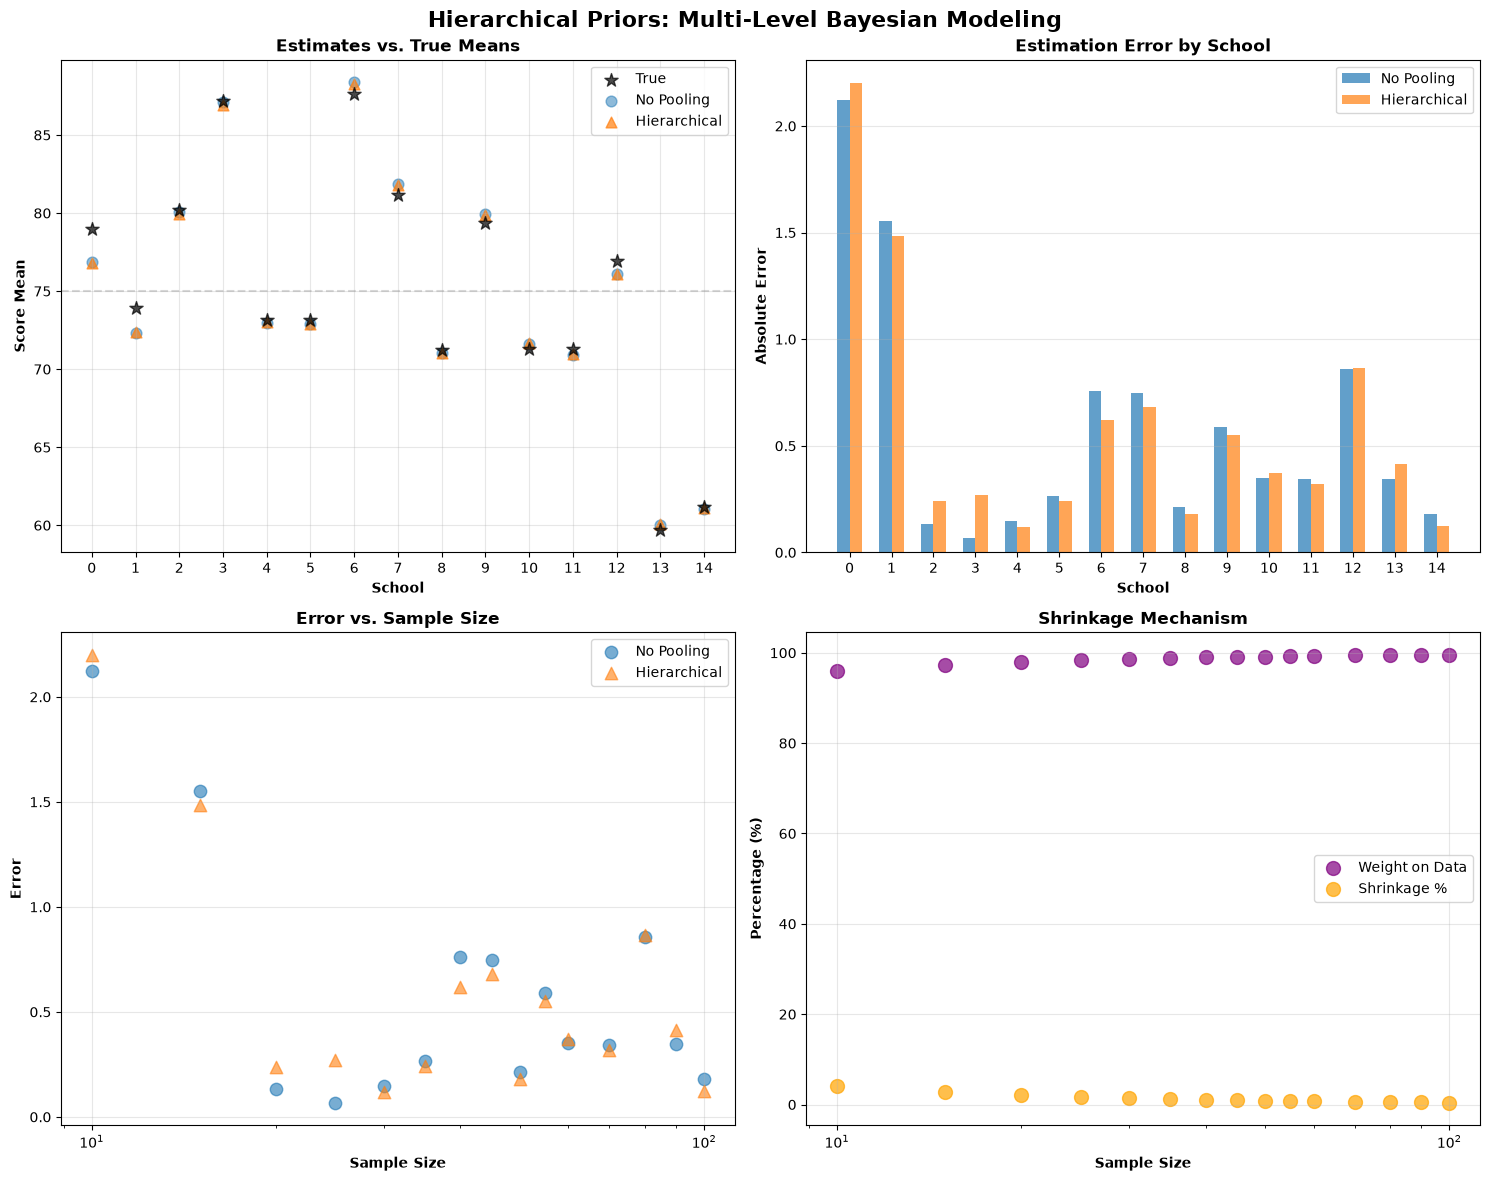

✓ Done


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Hierarchical Priors: Multi-Level Bayesian Modeling', fontsize=16, fontweight='bold')

school_idx = np.arange(n_schools)

ax = axes[0, 0]
ax.scatter(school_idx, true_school_means, s=100, alpha=0.7, label='True', marker='*', color='black', zorder=5)
ax.scatter(school_idx, no_pool_means, s=60, alpha=0.5, label='No Pooling', marker='o')
ax.scatter(school_idx, hierarchical_means, s=60, alpha=0.7, label='Hierarchical', marker='^')
ax.axhline(true_mu_0, color='gray', linestyle='--', alpha=0.3)
ax.set_xlabel('School', fontweight='bold')
ax.set_ylabel('Score Mean', fontweight='bold')
ax.set_title('Estimates vs. True Means', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xticks(school_idx)

ax = axes[0, 1]
errors_np = np.abs(no_pool_means - true_school_means)
errors_h = np.abs(hierarchical_means - true_school_means)
width = 0.3
ax.bar(school_idx - width/2, errors_np, width, label='No Pooling', alpha=0.7)
ax.bar(school_idx + width/2, errors_h, width, label='Hierarchical', alpha=0.7)
ax.set_xlabel('School', fontweight='bold')
ax.set_ylabel('Absolute Error', fontweight='bold')
ax.set_title('Estimation Error by School', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_xticks(school_idx)

ax = axes[1, 0]
ax.scatter(sample_sizes, errors_np, s=80, alpha=0.6, label='No Pooling', marker='o')
ax.scatter(sample_sizes, errors_h, s=80, alpha=0.6, label='Hierarchical', marker='^')
ax.set_xlabel('Sample Size', fontweight='bold')
ax.set_ylabel('Error', fontweight='bold')
ax.set_title('Error vs. Sample Size', fontweight='bold')
ax.set_xscale('log')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1, 1]
ax.scatter(sample_sizes, shrinkage_weights * 100, s=100, alpha=0.7, color='purple', label='Weight on Data')
ax.scatter(sample_sizes, (1 - shrinkage_weights) * 100, s=100, alpha=0.7, color='orange', label='Shrinkage %')
ax.set_xlabel('Sample Size', fontweight='bold')
ax.set_ylabel('Percentage (%)', fontweight='bold')
ax.set_title('Shrinkage Mechanism', fontweight='bold')
ax.set_xscale('log')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print('✓ Done')

## Key Takeaways

### What Are Hierarchical Priors?

Structured Bayesian beliefs about how groups relate to population parameters. Priors on priors.

### When to Use

1. Multiple groups with unequal sample sizes
2. Groups vary but are related
3. Need adaptive regularization
4. Want uncertainty quantification

### Real Applications

- Education: test scores across schools
- Healthcare: outcomes across hospitals
- Marketing: conversion rates across regions
- Manufacturing: quality across lines
- Clinical trials: effects across sites

### The Power

Simultaneously achieves:
1. Individual group adaptation
2. Information sharing across groups
3. Uncertainty quantification

Hierarchical priors are the **mechanism behind partial pooling**.